In [25]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from pathlib import Path
import matplotlib as mpl

# Keep text editable in AI
mpl.rcParams['pdf.fonttype'] = 42         # embed TrueType fonts in PDF
mpl.rcParams['ps.fonttype']  = 42
mpl.rcParams['svg.fonttype'] = 'none'     # write <text> in SVG (not paths)



def plot_subtype_correlation(
    csv_file,
    output_file,
    figsize=(20, 20),
    annot_fontsize=4,
    xtick_fontsize=6,
    ytick_fontsize=7,
    dpi=300
):
    # -----------------------------
    # Load correlation matrix
    # -----------------------------
    df = pd.read_csv(csv_file, index_col=0)

    # Make sure everything is numeric
    df = df.apply(pd.to_numeric, errors="coerce")

    # -----------------------------
    # Plot
    # -----------------------------
    fig, ax = plt.subplots(figsize=figsize)

    sns.heatmap(
        df,
        ax=ax,
        cmap="coolwarm",
        vmin=-1,
        vmax=1,
        center=0,
        annot=True,
        fmt=".2g",
        annot_kws={"fontsize": annot_fontsize},
        linewidths=0,
        xticklabels=True,   # <- force every column label
        yticklabels=True,   # <- force every row label too
        cbar_kws={
            "label": "",
            "ticks": [-1, -0.75, -0.5, -0.25, 0,
                      0.25, 0.5, 0.75, 1]
        }
    )

    # -----------------------------
    # Labels
    # -----------------------------
    ax.set_title(
        "Subtype expression similarity (pseudobulk r val)",
        fontsize=10,
        pad=8
    )

    ax.set_xlabel(
        "SEAAD subtypes",
        fontsize=9
    )

    ax.set_ylabel(
        "ROSMAP subtypes",
        fontsize=9
    )

    # Your original plots use vertical x-axis labels
    ax.set_xticklabels(
        ax.get_xticklabels(),
        rotation=90,
        ha="center",
        fontsize=xtick_fontsize
    )

    ax.set_yticklabels(
        ax.get_yticklabels(),
        rotation=0,
        fontsize=ytick_fontsize
    )

    # Colour-bar font size
    cbar = ax.collections[0].colorbar
    cbar.ax.tick_params(labelsize=7)

    plt.tight_layout()

    # Save both raster and vector if desired
    plt.savefig(
        output_file,
        dpi=dpi,
        bbox_inches="tight"
    )

    plt.show()

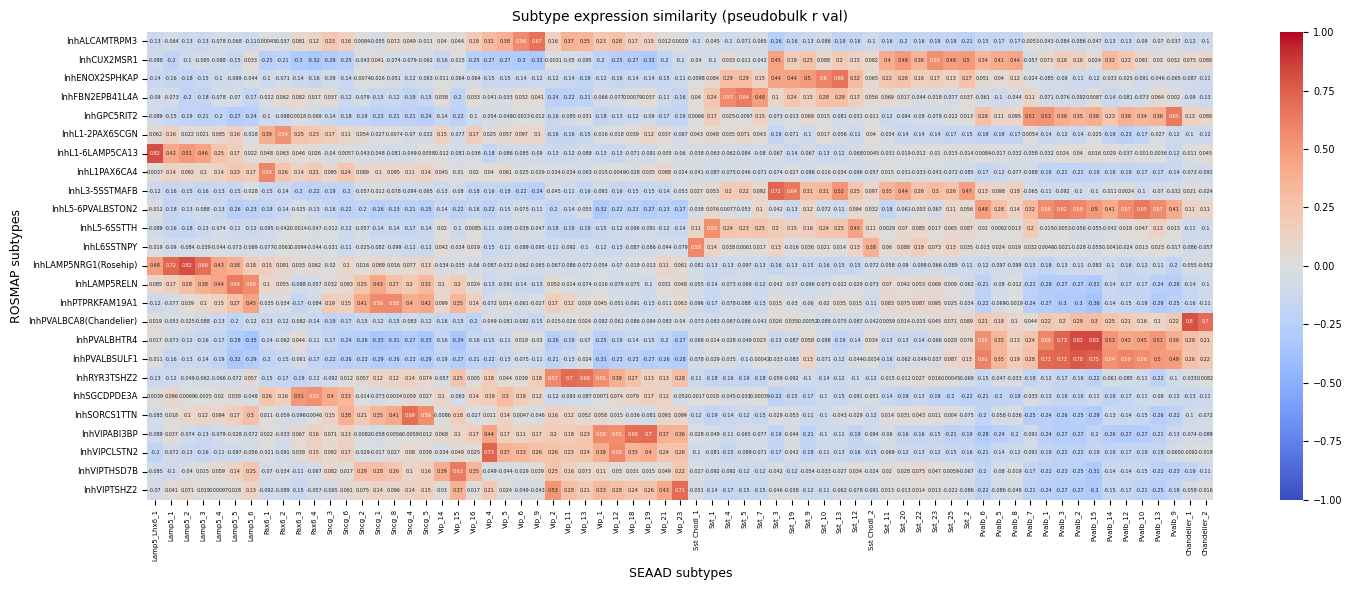

In [26]:
main_dir = Path("C:/Users/gabri/Documents/Data_projects/MCcharactertization/label_transfer")
inh_file = Path(main_dir, 'label_transfer_inhibPFC', "Alls_corr_ps.csv")
inh_out = Path(main_dir, 'label_transfer_inhibPFC', "Alls_corr_ps_heatmap.pdf")

plot_subtype_correlation(
    csv_file=inh_file,
    output_file=inh_out,
    figsize=(15, 6),
    annot_fontsize=3.5,
    xtick_fontsize=5,
    ytick_fontsize=6,
    dpi=300
)

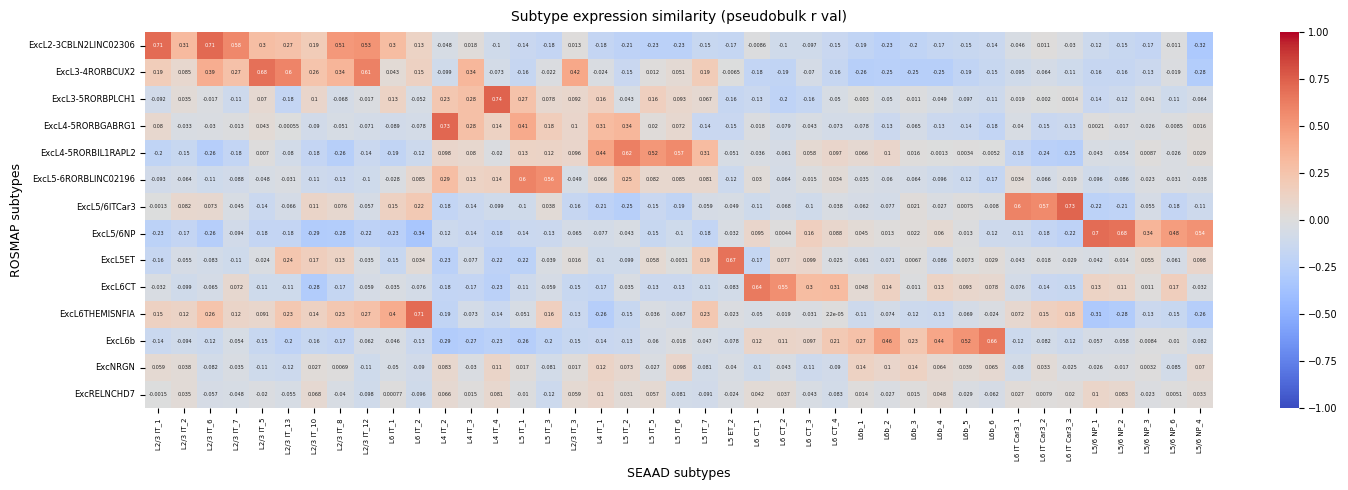

In [27]:
main_dir = Path("C:/Users/gabri/Documents/Data_projects/MCcharactertization/label_transfer")
exc_file = Path(main_dir, 'labels_heatmap_excitatory', "Alls_corr_ps.csv")
exc_out = Path(main_dir, 'labels_heatmap_excitatory', "Alls_corr_ps_heatmap.pdf")

plot_subtype_correlation(
    csv_file=exc_file,
    output_file=exc_out,
    figsize=(15, 5),
    annot_fontsize=3.5,
    xtick_fontsize=5,
    ytick_fontsize=6,
    dpi=300
)

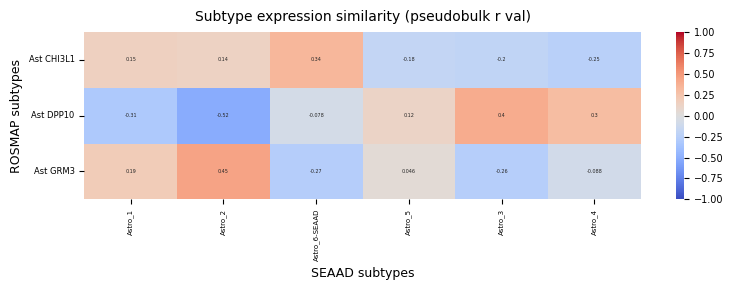

In [28]:
main_dir = Path("C:/Users/gabri/Documents/Data_projects/MCcharactertization/label_transfer")
ast_file = Path(main_dir,  "astrocyte_subtype_expression_similarity.csv")
ast_out = Path(main_dir,  "AST_Alls_corr_ps_heatmap.pdf")

plot_subtype_correlation(
    csv_file=ast_file,
    output_file=ast_out,
    figsize=(8, 3),
    annot_fontsize=3.5,
    xtick_fontsize=5,
    ytick_fontsize=6,
    dpi=300
)

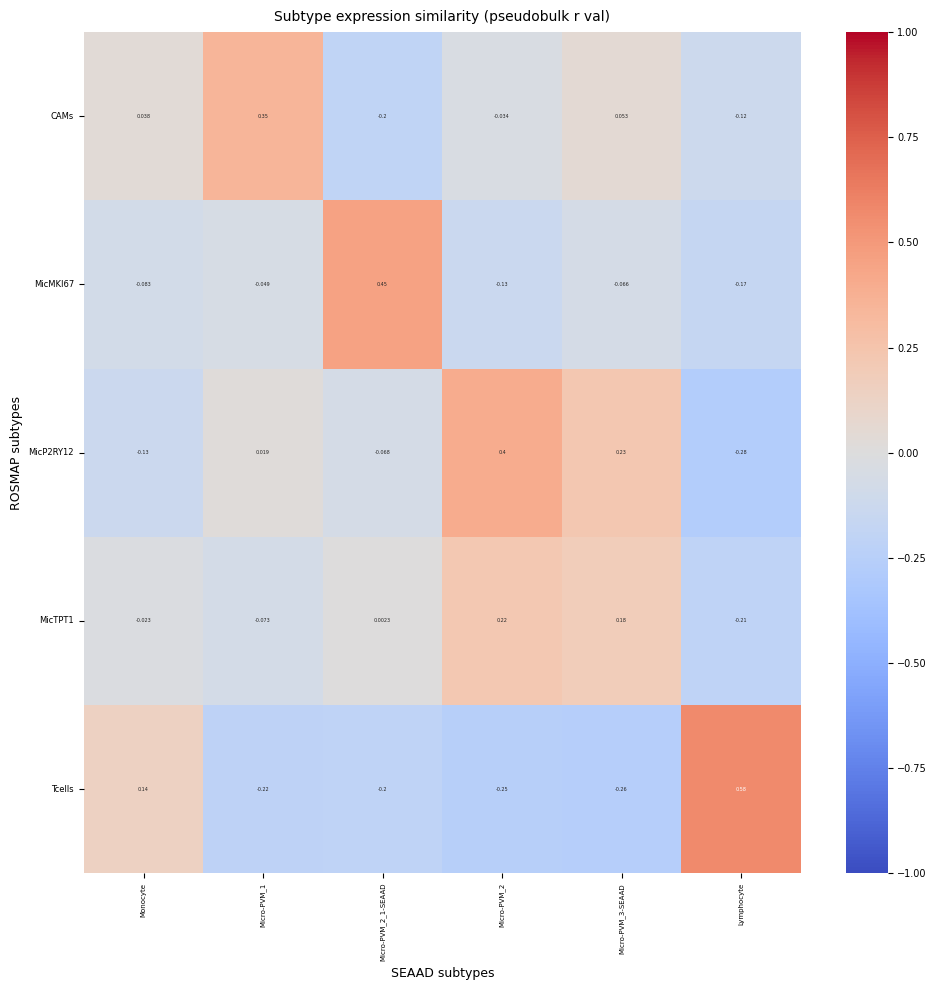

In [29]:
main_dir = Path("C:/Users/gabri/Documents/Data_projects/MCcharactertization/label_transfer")
imm_file = Path(main_dir, 'label_heatmap_immune', "Alls_corr_ps.csv")
imm_out = Path(main_dir, 'label_heatmap_immune', "Alls_corr_ps_heatmap.pdf")

plot_subtype_correlation(
    csv_file=imm_file,
    output_file=imm_out,
    figsize=(10, 10),
    annot_fontsize=3.5,
    xtick_fontsize=5,
    ytick_fontsize=6,
    dpi=300
)